# Phase 2 EDA Continue (2.1 to 2.4)

This notebook completes the remaining Phase 2 tasks.

We will do three things:
1. Finish the missing EDA plots and checks.
2. Do imbalance analysis with simple model comparisons.
3. Build feature engineering columns and leakage-safe mappings.

## Load data

This cell loads the cleaned merged dataset and review scores.

It tells us if files are loading correctly and gives the dataset shape.

In [13]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

base = Path("../datasets")
processed_path = base / "processed" / "olist_merged_clean.csv"
reviews_path = base / "raw" / "olist_order_reviews_dataset.csv"

df = pd.read_csv(processed_path)
reviews = pd.read_csv(reviews_path)

print("Main shape:", df.shape)
print("Reviews shape:", reviews.shape)
print("Late rate (%):", round(df["is_late"].mean() * 100, 2))

Main shape: (96189, 34)
Reviews shape: (99224, 7)
Late rate (%): 7.94


## Prepare helper columns

This cell creates time fields and joins average review score per order.

It tells us we now have all inputs needed for remaining EDA plots.

In [14]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in date_cols:
    df[c] = pd.to_datetime(df[c], errors="coerce")

reviews_agg = (
    reviews.groupby("order_id", as_index=False)["review_score"]
    .mean()
    .rename(columns={"review_score": "review_score_avg"})
)

df = df.merge(reviews_agg, on="order_id", how="left")

df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["purchase_quarter"] = df["order_purchase_timestamp"].dt.to_period("Q").astype(str)
df["purchase_day_of_week"] = df["order_purchase_timestamp"].dt.day_name()
df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour

def day_time(h):
    if h <= 6:
        return "Dawn"
    if h <= 12:
        return "Morning"
    if h <= 18:
        return "Afternoon"
    return "Night"

df["purchase_time_of_day"] = df["purchase_hour"].apply(day_time)

print("Columns now include review_score_avg and time helpers.")
print(df[["review_score_avg", "purchase_month", "purchase_quarter", "purchase_time_of_day"]].head(3))

Columns now include review_score_avg and time helpers.
   review_score_avg purchase_month purchase_quarter purchase_time_of_day
0               4.0        2017-10           2017Q4              Morning
1               4.0        2018-07           2018Q3                Night
2               5.0        2018-08           2018Q3              Morning


## 2.1 Core missing plots

This section finishes the remaining core EDA plots.

Each plot answers one checklist item directly.

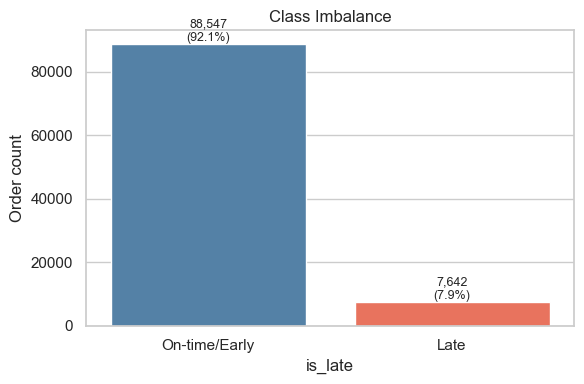

Class ratio (Late : On-time/Early) = 1 : 11.59


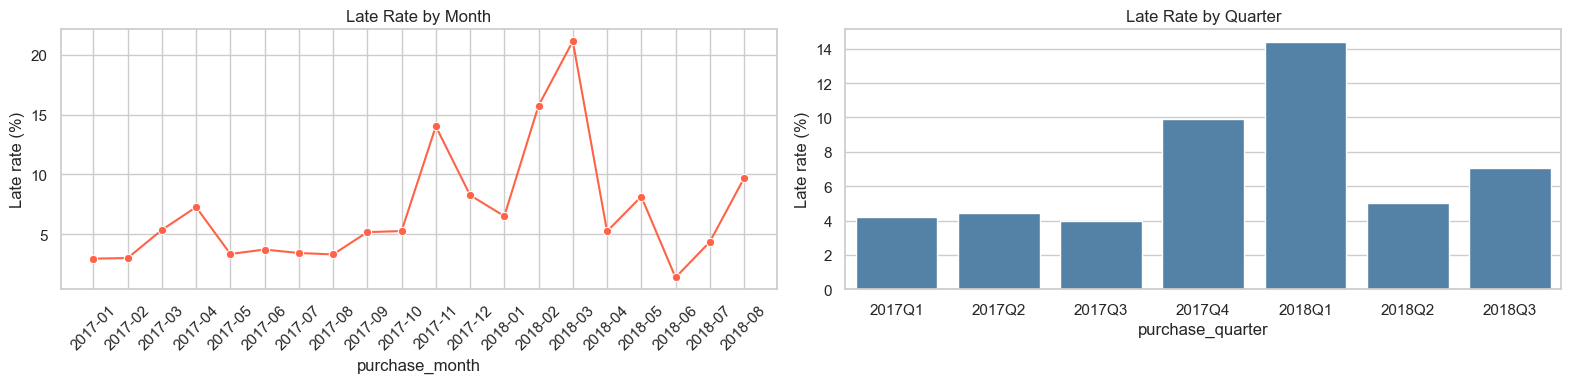

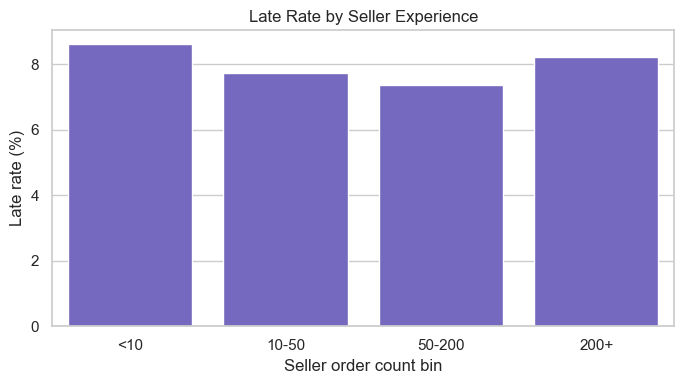

In [3]:
# Class imbalance bar
imb = df["is_late"].value_counts().rename(index={0: "On-time/Early", 1: "Late"})
plt.figure(figsize=(6, 4))
sns.barplot(x=imb.index, y=imb.values, palette=["steelblue", "tomato"])
plt.title("Class Imbalance")
plt.ylabel("Order count")
for i, v in enumerate(imb.values):
    plt.text(i, v, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()
print("Class ratio (Late : On-time/Early) = 1 :", round((df["is_late"]==0).sum() / max((df["is_late"]==1).sum(),1), 2))

# Late rate by month and quarter
monthly_late = df.groupby("purchase_month", as_index=False)["is_late"].mean()
monthly_late["late_rate_pct"] = monthly_late["is_late"] * 100
quarter_late = df.groupby("purchase_quarter", as_index=False)["is_late"].mean()
quarter_late["late_rate_pct"] = quarter_late["is_late"] * 100

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.lineplot(data=monthly_late, x="purchase_month", y="late_rate_pct", marker="o", ax=ax[0], color="tomato")
ax[0].set_title("Late Rate by Month")
ax[0].tick_params(axis="x", rotation=45)
ax[0].set_ylabel("Late rate (%)")

sns.barplot(data=quarter_late, x="purchase_quarter", y="late_rate_pct", ax=ax[1], color="steelblue")
ax[1].set_title("Late Rate by Quarter")
ax[1].set_ylabel("Late rate (%)")
plt.tight_layout()
plt.show()

# Late rate by seller experience bins
seller_key = (
    df["seller_zip_code_prefix"].astype(str) + "_" +
    df["seller_city"].astype(str) + "_" +
    df["seller_state"].astype(str)
)
df["seller_key"] = seller_key
seller_exp = df.groupby("seller_key", as_index=False).agg(
    seller_orders=("order_id", "count"),
    seller_late_rate=("is_late", "mean")
)
seller_exp["exp_bin"] = pd.cut(
    seller_exp["seller_orders"],
    bins=[0, 10, 50, 200, np.inf],
    labels=["<10", "10-50", "50-200", "200+"],
    right=False
)
exp_plot = seller_exp.groupby("exp_bin", as_index=False)["seller_late_rate"].mean()
exp_plot["seller_late_rate"] = exp_plot["seller_late_rate"] * 100

plt.figure(figsize=(7, 4))
sns.barplot(data=exp_plot, x="exp_bin", y="seller_late_rate", color="slateblue")
plt.title("Late Rate by Seller Experience")
plt.xlabel("Seller order count bin")
plt.ylabel("Late rate (%)")
plt.tight_layout()
plt.show()

## 2.1 Review and correlation plots

This section links delay to review score and shows feature relationships.

It tells us how customer satisfaction changes with delay and which numeric fields are associated with late deliveries.

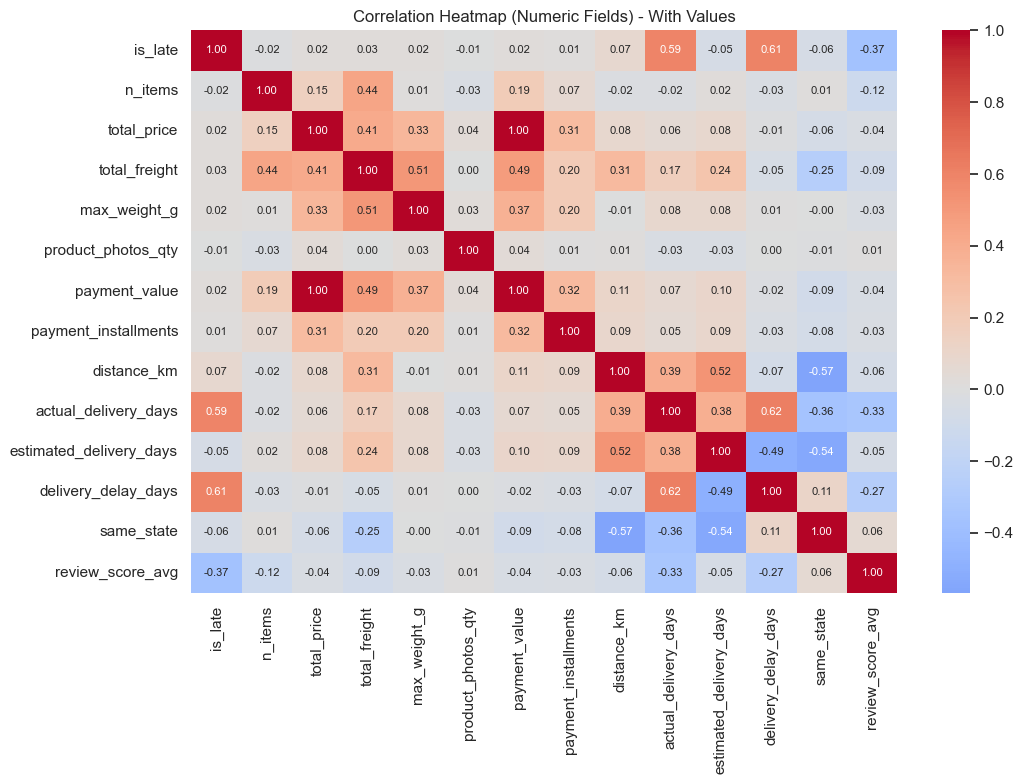

In [4]:
# Correlation heatmap with numbers
num_cols_local = [
    "is_late", "n_items", "total_price", "total_freight", "max_weight_g", "product_photos_qty",
    "payment_value", "payment_installments", "distance_km", "actual_delivery_days",
    "estimated_delivery_days", "delivery_delay_days", "same_state", "review_score_avg"
]
num_cols_local = [c for c in num_cols_local if c in df.columns]
corr_num = df[num_cols_local].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_num, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Correlation Heatmap (Numeric Fields) - With Values")
plt.tight_layout()
plt.show()

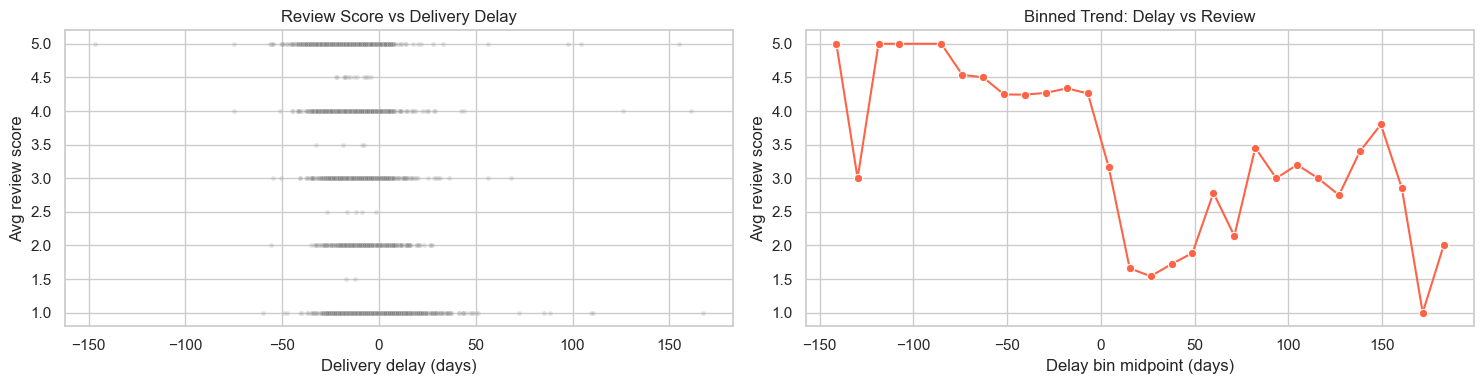

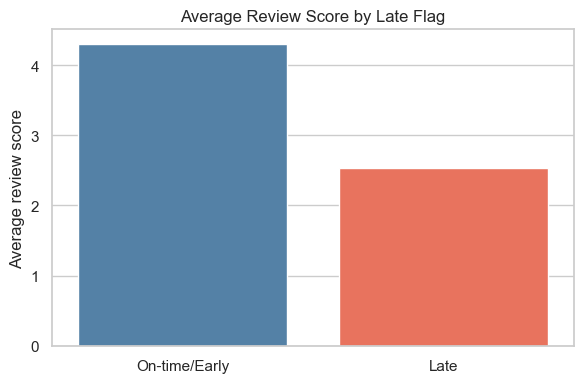

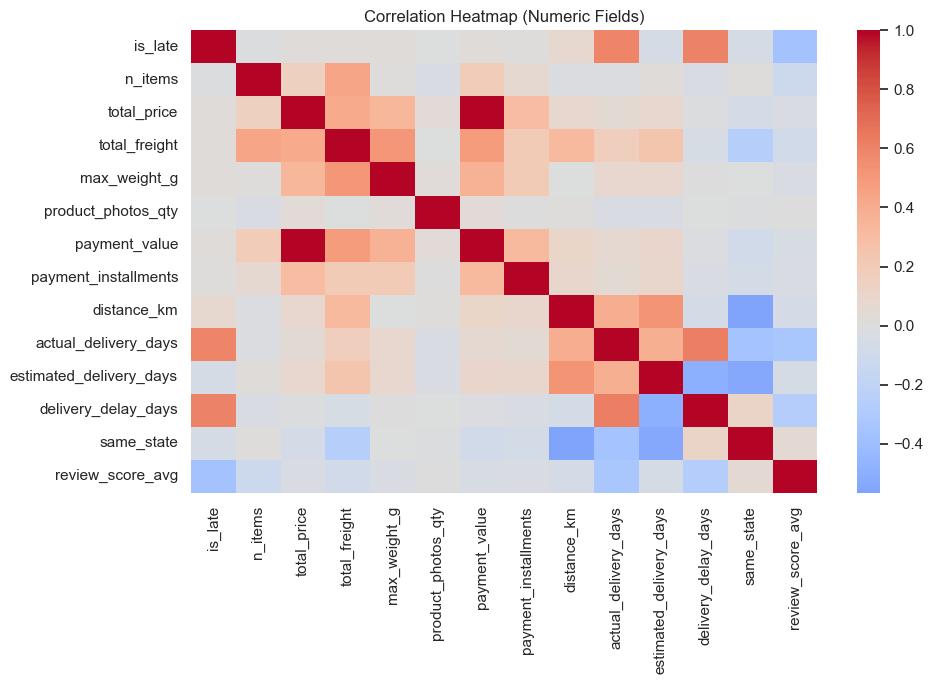

Spearman correlation with is_late:
is_late                    1.000000
delivery_delay_days        0.468409
actual_delivery_days       0.397434
distance_km                0.061483
total_freight              0.046118
payment_value              0.024991
total_price                0.020449
max_weight_g               0.017586
payment_installments       0.008249
product_photos_qty        -0.011964
n_items                   -0.018908
estimated_delivery_days   -0.042442
same_state                -0.058372
review_score_avg          -0.296869
Name: is_late, dtype: float64


In [3]:
# Review score vs delivery delay
rev_delay = df[["delivery_delay_days", "review_score_avg"]].dropna().copy()
rev_delay["delay_bin"] = pd.cut(rev_delay["delivery_delay_days"], bins=30)
trend = rev_delay.groupby("delay_bin", as_index=False)["review_score_avg"].mean()
trend["delay_mid"] = trend["delay_bin"].apply(lambda x: (x.left + x.right) / 2)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.scatterplot(data=rev_delay.sample(min(12000, len(rev_delay)), random_state=42),
                x="delivery_delay_days", y="review_score_avg", alpha=0.2, s=12, ax=ax[0], color="gray")
ax[0].set_title("Review Score vs Delivery Delay")
ax[0].set_xlabel("Delivery delay (days)")
ax[0].set_ylabel("Avg review score")

sns.lineplot(data=trend.dropna(), x="delay_mid", y="review_score_avg", marker="o", ax=ax[1], color="tomato")
ax[1].set_title("Binned Trend: Delay vs Review")
ax[1].set_xlabel("Delay bin midpoint (days)")
ax[1].set_ylabel("Avg review score")
plt.tight_layout()
plt.show()

# Avg review by is_late
avg_review_late = df.groupby("is_late", as_index=False)["review_score_avg"].mean()
avg_review_late["is_late"] = avg_review_late["is_late"].map({0: "On-time/Early", 1: "Late"})
plt.figure(figsize=(6, 4))
sns.barplot(data=avg_review_late, x="is_late", y="review_score_avg", palette=["steelblue", "tomato"])
plt.title("Average Review Score by Late Flag")
plt.xlabel("")
plt.ylabel("Average review score")
plt.tight_layout()
plt.show() 

# Correlation heatmap (numeric vs is_late)
num_cols = [
    "is_late", "n_items", "total_price", "total_freight", "max_weight_g", "product_photos_qty",
    "payment_value", "payment_installments", "distance_km", "actual_delivery_days",
    "estimated_delivery_days", "delivery_delay_days", "same_state", "review_score_avg"
]
num_cols = [c for c in num_cols if c in df.columns]
corr = df[num_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap (Numeric Fields)")
plt.tight_layout()
plt.show()

# Spearman check for skewed features
spearman = df[num_cols].corr(method="spearman", numeric_only=True)
print("Spearman correlation with is_late:")
print(spearman["is_late"].sort_values(ascending=False))

## 2.1 Distribution and repo-based extra plots

This section finishes the extra plots from the repo suggestions.

It tells us seasonality, volume patterns, route efficiency, SP dominance, and outlier spread.

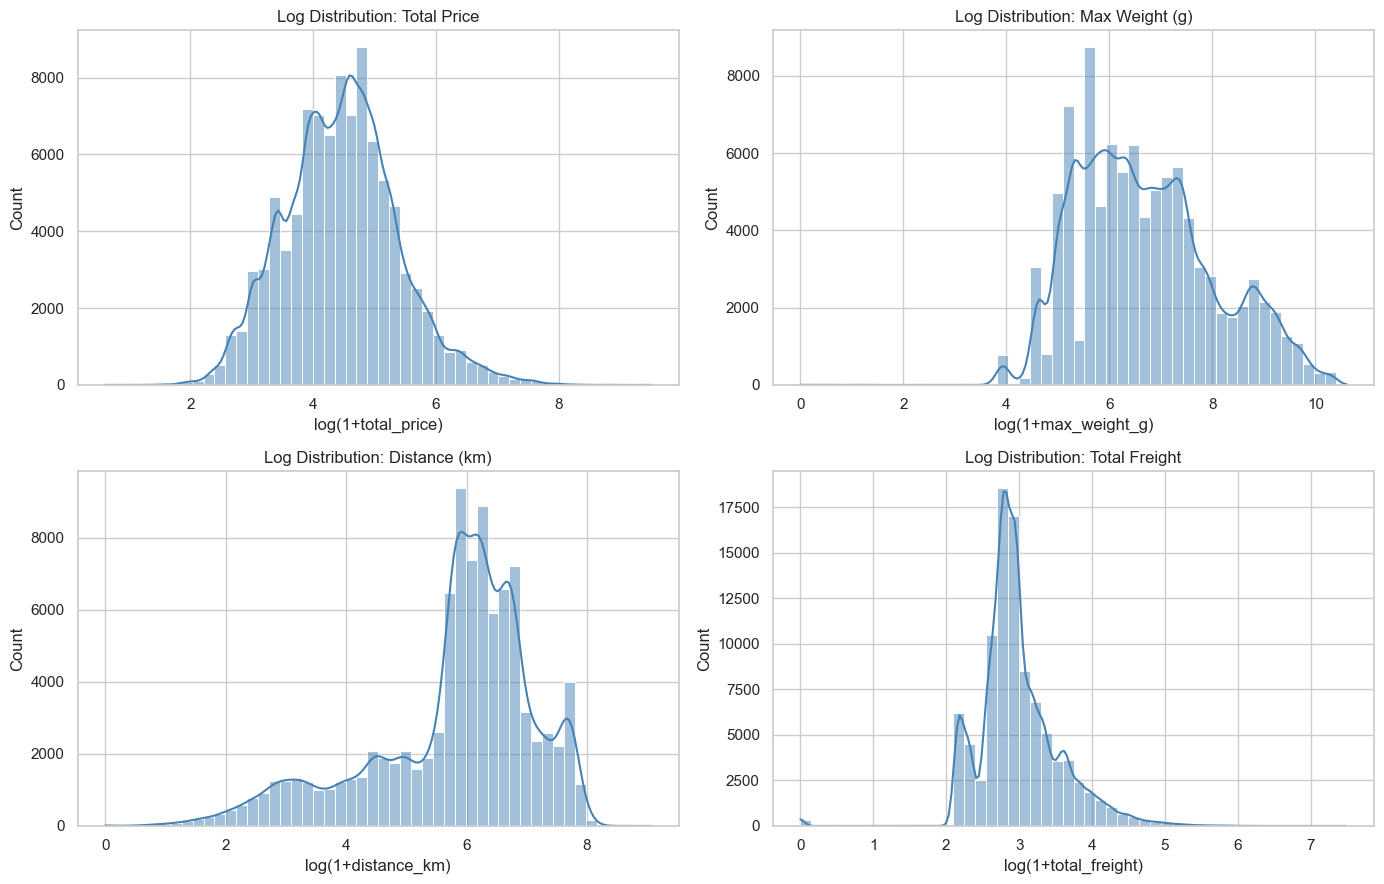

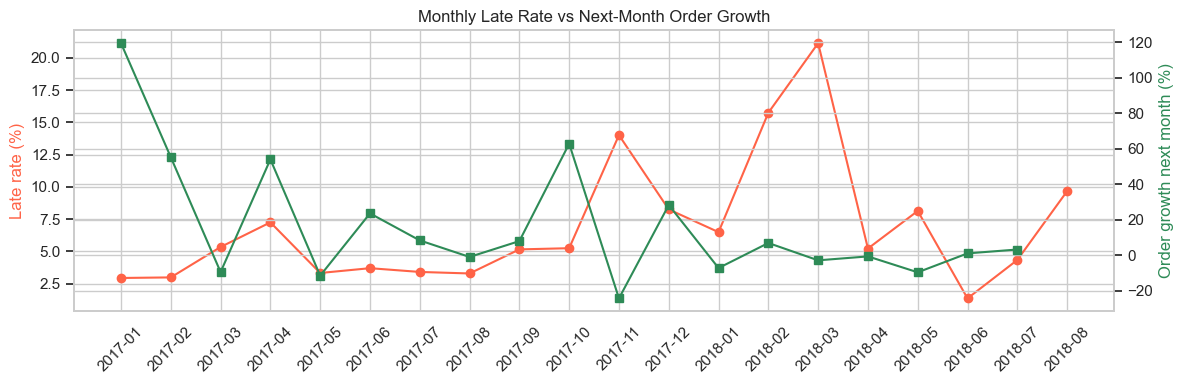

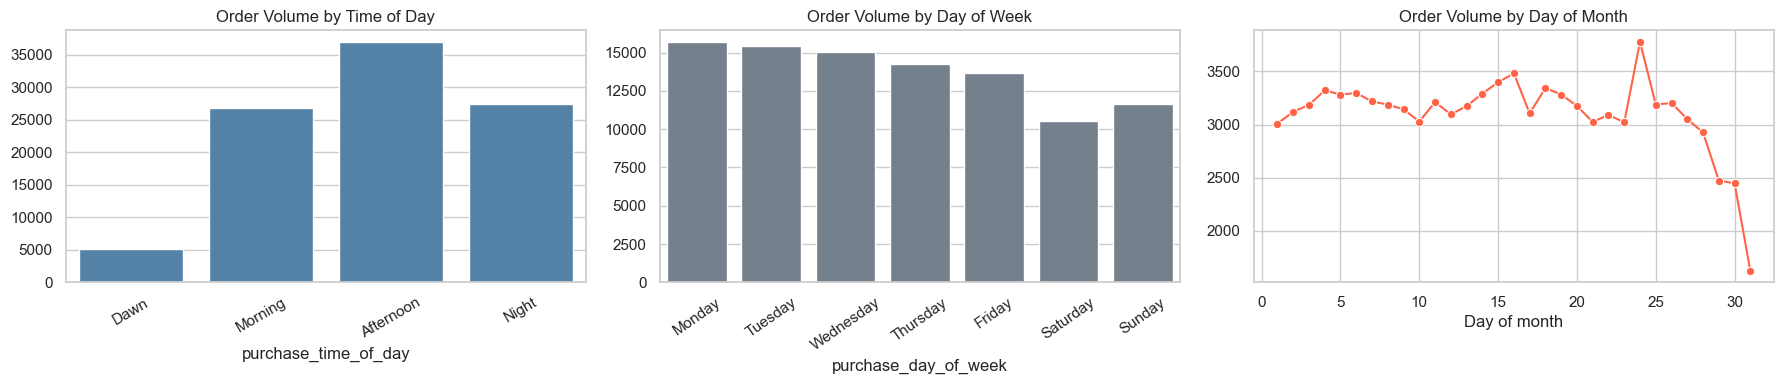

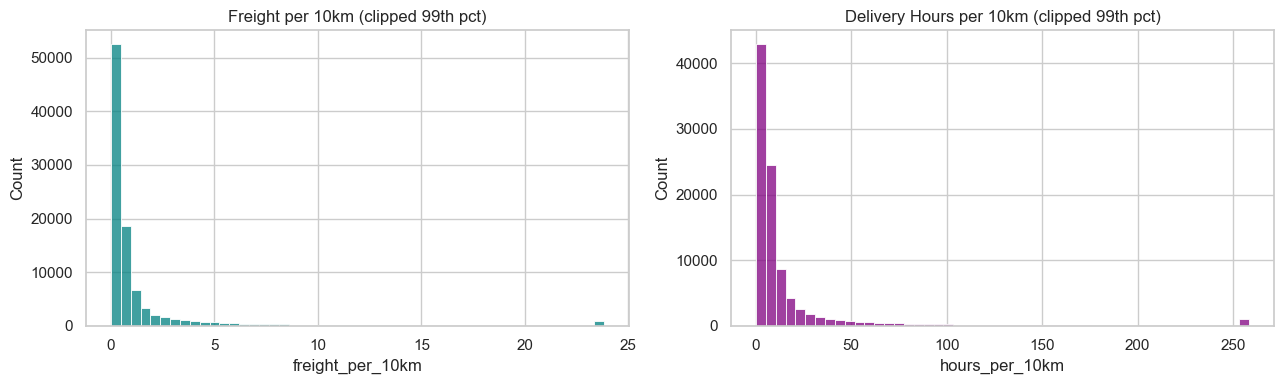

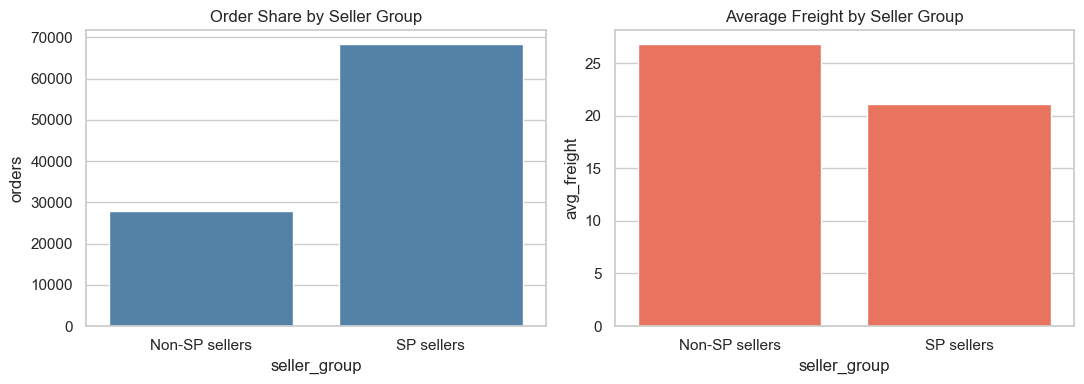

SP seller order share (%): 70.96


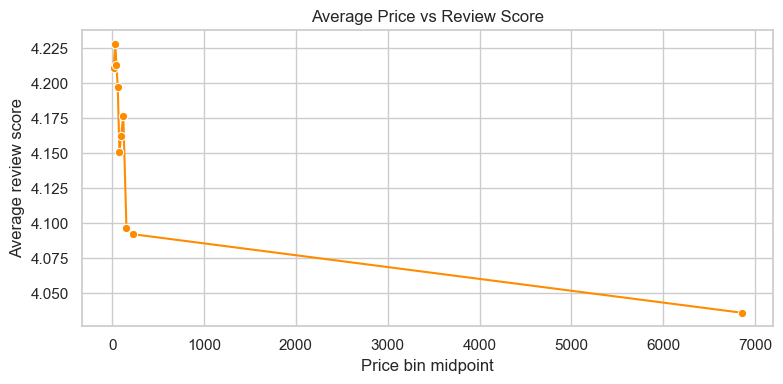

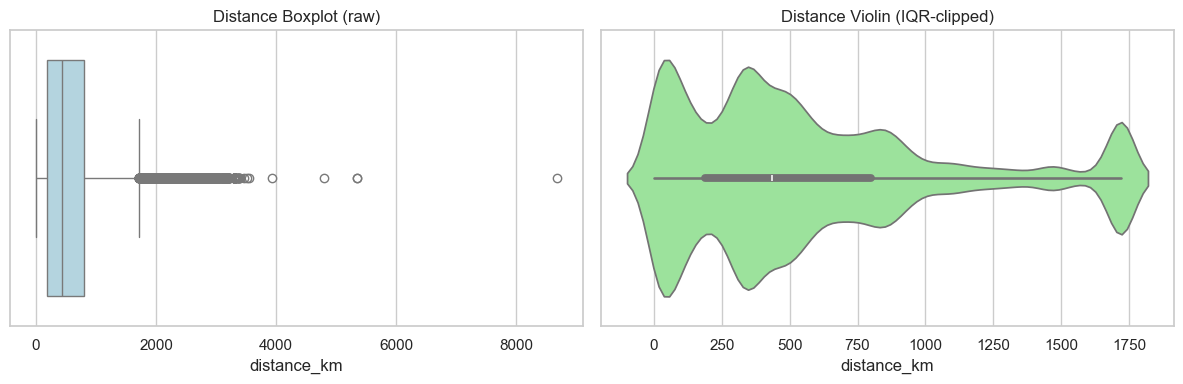

IQR upper bound for distance_km: 1720.61


In [4]:
# Distribution plots with log scales for skewed columns
plot_cols = {
    "total_price": "Total Price",
    "max_weight_g": "Max Weight (g)",
    "distance_km": "Distance (km)",
    "total_freight": "Total Freight",
}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (c, title) in zip(axes.flatten(), plot_cols.items()):
    vals = df[c].dropna()
    sns.histplot(np.log1p(vals), bins=50, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Log Distribution: {title}")
    ax.set_xlabel(f"log(1+{c})")
plt.tight_layout()
plt.show()

# Dual-axis monthly late rate vs next-month order growth
monthly = df.groupby("purchase_month", as_index=False).agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean")
)
monthly["late_rate_pct"] = monthly["late_rate"] * 100
monthly["order_growth_next_month_pct"] = monthly["orders"].pct_change().shift(-1) * 100

fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()
ax1.plot(monthly["purchase_month"], monthly["late_rate_pct"], color="tomato", marker="o", label="Late rate (%)")
ax2.plot(monthly["purchase_month"], monthly["order_growth_next_month_pct"], color="seagreen", marker="s", label="Next month order growth (%)")
ax1.tick_params(axis="x", rotation=45)
ax1.set_ylabel("Late rate (%)", color="tomato")
ax2.set_ylabel("Order growth next month (%)", color="seagreen")
ax1.set_title("Monthly Late Rate vs Next-Month Order Growth")
plt.tight_layout()
plt.show()

# Order volume patterns: time of day, week day, month day
tod = df["purchase_time_of_day"].value_counts().reindex(["Dawn", "Morning", "Afternoon", "Night"])
dow = df["purchase_day_of_week"].value_counts().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
dom = df["order_purchase_timestamp"].dt.day.value_counts().sort_index()

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.barplot(x=tod.index, y=tod.values, ax=ax[0], color="steelblue")
ax[0].set_title("Order Volume by Time of Day")
ax[0].tick_params(axis="x", rotation=30)

sns.barplot(x=dow.index, y=dow.values, ax=ax[1], color="slategray")
ax[1].set_title("Order Volume by Day of Week")
ax[1].tick_params(axis="x", rotation=35)

sns.lineplot(x=dom.index, y=dom.values, ax=ax[2], marker="o", color="tomato")
ax[2].set_title("Order Volume by Day of Month")
ax[2].set_xlabel("Day of month")
plt.tight_layout()
plt.show()

# Freight normalized metrics
norm_df = df[["distance_km", "total_freight", "actual_delivery_days"]].copy()
norm_df = norm_df[norm_df["distance_km"] > 0]
norm_df["freight_per_10km"] = norm_df["total_freight"] * 10 / norm_df["distance_km"]
norm_df["hours_per_10km"] = (norm_df["actual_delivery_days"] * 24) * 10 / norm_df["distance_km"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(norm_df["freight_per_10km"].clip(upper=norm_df["freight_per_10km"].quantile(0.99)), bins=50, ax=ax[0], color="teal")
ax[0].set_title("Freight per 10km (clipped 99th pct)")
sns.histplot(norm_df["hours_per_10km"].clip(upper=norm_df["hours_per_10km"].quantile(0.99)), bins=50, ax=ax[1], color="purple")
ax[1].set_title("Delivery Hours per 10km (clipped 99th pct)")
plt.tight_layout()
plt.show()

# SP dominance chart
df["is_sp_seller"] = (df["seller_state"] == "SP").astype(int)
sp_summary = df.groupby("is_sp_seller", as_index=False).agg(
    orders=("order_id", "count"),
    avg_freight=("total_freight", "mean")
)
sp_summary["seller_group"] = sp_summary["is_sp_seller"].map({1: "SP sellers", 0: "Non-SP sellers"})

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=sp_summary, x="seller_group", y="orders", ax=ax[0], color="steelblue")
ax[0].set_title("Order Share by Seller Group")
sns.barplot(data=sp_summary, x="seller_group", y="avg_freight", ax=ax[1], color="tomato")
ax[1].set_title("Average Freight by Seller Group")
plt.tight_layout()
plt.show()
print("SP seller order share (%):", round(df["is_sp_seller"].mean()*100, 2))

# Avg price vs review score
a = df[["total_price", "review_score_avg"]].dropna().copy()
a["price_bin"] = pd.qcut(a["total_price"], q=10, duplicates="drop")
ap = a.groupby("price_bin", as_index=False)["review_score_avg"].mean()
ap["price_mid"] = ap["price_bin"].apply(lambda x: (x.left + x.right) / 2)
plt.figure(figsize=(8, 4))
sns.lineplot(data=ap, x="price_mid", y="review_score_avg", marker="o", color="darkorange")
plt.title("Average Price vs Review Score")
plt.xlabel("Price bin midpoint")
plt.ylabel("Average review score")
plt.tight_layout()
plt.show()

# IQR outlier visualization for distance
d = df["distance_km"].dropna()
q1, q3 = d.quantile(0.25), d.quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=d, ax=ax[0], color="lightblue")
ax[0].set_title("Distance Boxplot (raw)")
sns.violinplot(x=d.clip(upper=upper), ax=ax[1], color="lightgreen")
ax[1].set_title("Distance Violin (IQR-clipped)")
plt.tight_layout()
plt.show()

print("IQR upper bound for distance_km:", round(upper, 2))

## 2.2 Imbalance analysis

This section compares class-weight, SMOTE, and threshold tuning.

It tells us which approach gives better recall and lower business cost.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, recall_score, precision_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    SMOTE_OK = True
except Exception:
    SMOTE_OK = False

imb_ratio = (df["is_late"] == 0).sum() / max((df["is_late"] == 1).sum(), 1)
print("Class ratio (majority/minority):", round(imb_ratio, 2))

# Temporal split for this analysis
train_mask = (df["order_purchase_timestamp"] < "2018-01-01")
val_mask = (df["order_purchase_timestamp"] >= "2018-01-01") & (df["order_purchase_timestamp"] < "2018-07-01")

use_cols = [
    "distance_km", "total_price", "total_freight", "max_weight_g", "n_items",
    "payment_installments", "same_state", "estimated_delivery_days", "product_photos_qty",
    "payment_type", "customer_state", "seller_state", "primary_category"
]
use_cols = [c for c in use_cols if c in df.columns]

X_train = df.loc[train_mask, use_cols].copy()
y_train = df.loc[train_mask, "is_late"].astype(int)
X_val = df.loc[val_mask, use_cols].copy()
y_val = df.loc[val_mask, "is_late"].astype(int)

num_features = [c for c in use_cols if pd.api.types.is_numeric_dtype(df[c])]
cat_features = [c for c in use_cols if c not in num_features]

pre = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ]
)

def evaluate_probs(y_true, y_prob, label):
    y_pred_05 = (y_prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred_05).ravel()
    cost_05 = fp * 15 + fn * 155

    thresholds = np.arange(0.05, 0.96, 0.01)
    best = {"thr": 0.5, "cost": cost_05, "recall": recall_score(y_true, y_pred_05), "precision": precision_score(y_true, y_pred_05, zero_division=0), "f1": f1_score(y_true, y_pred_05, zero_division=0)}
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        cost = fp * 15 + fn * 155
        if cost < best["cost"]:
            best = {
                "thr": float(t),
                "cost": int(cost),
                "recall": float(recall_score(y_true, y_pred, zero_division=0)),
                "precision": float(precision_score(y_true, y_pred, zero_division=0)),
                "f1": float(f1_score(y_true, y_pred, zero_division=0)),
            }

    return {
        "method": label,
        "auc": roc_auc_score(y_true, y_prob),
        "cost@0.5": int(cost_05),
        "best_threshold": best["thr"],
        "best_cost": best["cost"],
        "best_recall": round(best["recall"], 4),
        "best_precision": round(best["precision"], 4),
        "best_f1": round(best["f1"], 4),
    }

rows = []

# 1) Class-weight balanced
pipe_bal = Pipeline([
    ("pre", pre),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))
])
pipe_bal.fit(X_train, y_train)
prob_bal = pipe_bal.predict_proba(X_val)[:, 1]
rows.append(evaluate_probs(y_val, prob_bal, "class_weight=balanced"))

# 2) SMOTE inside pipeline (if available)
if SMOTE_OK:
    pipe_smote = ImbPipeline([
        ("pre", pre),
        ("smote", SMOTE(random_state=42)),
        ("clf", LogisticRegression(max_iter=2000))
    ])
    pipe_smote.fit(X_train, y_train)
    prob_smote = pipe_smote.predict_proba(X_val)[:, 1]
    rows.append(evaluate_probs(y_val, prob_smote, "SMOTE + Logistic"))
else:
    print("imblearn not available in this kernel, so SMOTE cell uses fallback note only.")

# 3) Threshold tuning shown on the class-weight model
rows.append({
    "method": "threshold tuning (on class_weight model)",
    "auc": rows[0]["auc"],
    "cost@0.5": rows[0]["cost@0.5"],
    "best_threshold": rows[0]["best_threshold"],
    "best_cost": rows[0]["best_cost"],
    "best_recall": rows[0]["best_recall"],
    "best_precision": rows[0]["best_precision"],
    "best_f1": rows[0]["best_f1"],
})

imb_results = pd.DataFrame(rows)
imb_results

Class ratio (majority/minority): 11.59


,method,auc,cost@0.5,best_threshold,best_cost,best_recall,best_precision,best_f1
0,class_weight=balanced,0.711760,406780,0.46,401385,0.6862,0.1632,0.2637
1,SMOTE + Logistic,0.708089,411175,0.47,409105,0.6554,0.1645,0.2629
2,threshold tuning (on class_weight model),0.711760,406780,0.46,401385,0.6862,0.1632,0.2637


## 2.3 Feature engineering

This section creates the full Phase 2.3 feature set with train-only target encoding where needed.

It tells us how many model-ready features we now have and shows sample rows.

In [5]:
feat = df.copy()

# ---------- Temporal ----------
feat["month"] = feat["order_purchase_timestamp"].dt.month
feat["quarter"] = feat["order_purchase_timestamp"].dt.quarter
feat["day_of_week"] = feat["order_purchase_timestamp"].dt.dayofweek
feat["hour_of_day"] = feat["order_purchase_timestamp"].dt.hour
feat["is_weekend"] = feat["day_of_week"].isin([5, 6]).astype(int)
feat["is_peak_season"] = feat["month"].isin([4, 5, 6]).astype(int)
feat["week_of_year"] = feat["order_purchase_timestamp"].dt.isocalendar().week.astype(int)
feat["days_since_platform_launch"] = (feat["order_purchase_timestamp"] - pd.Timestamp("2016-01-01")).dt.days
feat["is_holiday_season"] = feat["month"].isin([11, 12]).astype(int)
feat["is_end_of_month"] = (feat["order_purchase_timestamp"].dt.day >= 24).astype(int)
feat["purchase_time_of_day"] = feat["hour_of_day"].apply(day_time)

# ---------- Geographic ----------
feat["same_city"] = (feat["customer_city"].astype(str).str.lower() == feat["seller_city"].astype(str).str.lower()).astype(int)

region_map = {
    "N": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "NE": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "SE": ["ES", "MG", "RJ", "SP"],
    "S": ["PR", "RS", "SC"],
    "CO": ["DF", "GO", "MT", "MS"],
}
state_to_region = {s: r for r, states in region_map.items() for s in states}
feat["customer_region"] = feat["customer_state"].map(state_to_region).fillna("UNK")
NNE_states = ["AM", "PA", "MA", "CE", "RN", "PB", "PE", "AL", "SE", "BA", "PI", "TO", "AP", "RR", "AC", "RO"]
feat["is_north_northeast_customer"] = feat["customer_state"].isin(NNE_states).astype(int)

# ---------- Order ----------
feat["total_order_value"] = feat["total_price"]
feat["total_freight_cost"] = feat["total_freight"]
feat["avg_item_price"] = feat["total_order_value"] / feat["n_items"].replace(0, np.nan)
feat["freight_to_value_ratio"] = feat["total_freight_cost"] / feat["total_order_value"].replace(0, np.nan)
feat["freight_per_item"] = feat["total_freight_cost"] / feat["n_items"].replace(0, np.nan)

# ---------- Product ----------
feat["product_volume_cm3"] = feat["max_length_cm"] * feat["max_height_cm"] * feat["max_width_cm"]
feat["product_weight_g"] = feat["max_weight_g"]
feat["is_bulky"] = ((feat["product_weight_g"] > 10000) | (feat["product_volume_cm3"] > 100000)).astype(int)
feat["product_category"] = feat["primary_category"].fillna("unknown")
feat["is_furniture"] = feat["product_category"].str.contains("furniture", case=False, na=False).astype(int)
feat["weight_to_price_ratio"] = feat["product_weight_g"] / feat["total_order_value"].replace(0, np.nan)

# ---------- Payment ----------
feat["payment_per_installment"] = feat["payment_value"] / feat["payment_installments"].replace(0, np.nan)
feat["high_installment_flag"] = (feat["payment_installments"] > 6).astype(int)
pay_ohe = pd.get_dummies(feat["payment_type"], prefix="payment_type")
for col in ["payment_type_credit_card", "payment_type_boleto", "payment_type_debit_card", "payment_type_voucher"]:
    if col not in pay_ohe.columns:
        pay_ohe[col] = 0
feat = pd.concat([feat, pay_ohe], axis=1)

# ---------- Seller ----------
if "seller_key" not in feat.columns:
    feat["seller_key"] = (
        feat["seller_zip_code_prefix"].astype(str) + "_" +
        feat["seller_city"].astype(str) + "_" +
        feat["seller_state"].astype(str)
    )

feat["seller_order_count"] = feat.groupby("seller_key")["order_id"].transform("count")
feat["seller_state_volume"] = feat.groupby("seller_state")["order_id"].transform("count")

feat = feat.sort_values(["seller_key", "order_purchase_timestamp"]).copy()
feat["seller_monthly_volume"] = 0.0

# Index-safe rolling assignment to avoid duplicate-label reindex errors.
for _, idx in feat.groupby("seller_key").groups.items():
    g = feat.loc[idx].sort_values("order_purchase_timestamp")
    counts = (
        g.set_index("order_purchase_timestamp")["order_id"]
        .rolling("30D")
        .count()
        .to_numpy()
    )
    feat.loc[g.index, "seller_monthly_volume"] = counts

feat["seller_monthly_volume"] = feat["seller_monthly_volume"].fillna(0)

# ---------- Time pressure ----------
feat["is_urgent"] = (feat["estimated_delivery_days"] < 7).astype(int)
feat["is_long_window"] = (feat["estimated_delivery_days"] > 20).astype(int)

# ---------- Interaction ----------
feat["distance_x_weight"] = feat["distance_km"] * feat["product_weight_g"]
feat["distance_x_bulky"] = feat["distance_km"] * feat["is_bulky"]
feat["peak_x_distance"] = feat["is_peak_season"] * feat["distance_km"]
feat["freight_x_distance"] = feat["total_freight_cost"] / feat["distance_km"].clip(lower=1)
feat["seller_exp_x_distance"] = (1 / feat["seller_order_count"].replace(0, np.nan)) * feat["distance_km"]
feat["price_per_km"] = feat["total_order_value"] / feat["distance_km"].clip(lower=1)
p75 = feat["total_order_value"].quantile(0.75)
feat["is_high_value_and_high_distance"] = ((feat["total_order_value"] > p75) & (feat["distance_km"] > 500)).astype(int)

# ---------- Optional ----------
feat["order_purchased_to_approved"] = (feat["order_approved_at"] - feat["order_purchase_timestamp"]).dt.total_seconds() / 86400

# ---------- Train-only target encoding ----------
train_te = feat["order_purchase_timestamp"] < "2018-01-01"

def te_map(frame, key_col, target_col="is_late", mask=train_te):
    m = frame.loc[mask].groupby(key_col)[target_col].mean()
    g = frame.loc[mask, target_col].mean()
    return frame[key_col].map(m).fillna(g)

feat["customer_state_te"] = te_map(feat, "customer_state")
feat["seller_state_te"] = te_map(feat, "seller_state")
feat["category_late_rate"] = te_map(feat, "product_category")
feat["route_key"] = feat["seller_state"].astype(str) + "->" + feat["customer_state"].astype(str)
feat["route_late_rate"] = te_map(feat, "route_key")
feat["seller_late_rate"] = te_map(feat, "seller_key")

# seller_avg_review from training reviews only
seller_review_map = feat.loc[train_te].groupby("seller_key")["review_score_avg"].mean()
feat["seller_avg_review"] = feat["seller_key"].map(seller_review_map).fillna(feat.loc[train_te, "review_score_avg"].mean())

feature_cols_created = [
    "month", "quarter", "day_of_week", "hour_of_day", "is_weekend", "is_peak_season", "week_of_year",
    "days_since_platform_launch", "is_holiday_season", "is_end_of_month", "purchase_time_of_day",
    "same_city", "customer_region", "is_north_northeast_customer", "total_order_value", "total_freight_cost",
    "avg_item_price", "freight_to_value_ratio", "freight_per_item", "product_volume_cm3", "product_weight_g",
    "is_bulky", "product_category", "is_furniture", "weight_to_price_ratio", "payment_per_installment",
    "high_installment_flag", "seller_order_count", "seller_late_rate", "seller_avg_review", "seller_state_volume",
    "seller_monthly_volume", "is_urgent", "is_long_window", "distance_x_weight", "distance_x_bulky",
    "peak_x_distance", "freight_x_distance", "seller_exp_x_distance", "price_per_km", "is_high_value_and_high_distance",
    "order_purchased_to_approved", "is_sp_seller", "customer_state_te", "seller_state_te", "category_late_rate",
    "route_late_rate"
]
feature_cols_created = [c for c in feature_cols_created if c in feat.columns]

print("Created feature columns:", len(feature_cols_created))
feat[feature_cols_created].head(3)

Created feature columns: 47


,month,quarter,day_of_week,hour_of_day,is_weekend,is_peak_season,week_of_year,days_since_platform_launch,is_holiday_season,is_end_of_month,...,freight_x_distance,seller_exp_x_distance,price_per_km,is_high_value_and_high_distance,order_purchased_to_approved,is_sp_seller,customer_state_te,seller_state_te,category_late_rate,route_late_rate
34446,8,3,4,16,0,0,31,581,0,0,...,0.064704,62.250052,0.177510,1,0.009537,1,0.053348,0.070336,0.050505,0.058304
95526,8,3,0,16,0,0,32,584,0,0,...,0.056716,35.515596,0.148627,0,0.013530,1,0.033416,0.070336,0.050505,0.034611
70708,10,4,2,0,0,0,42,656,0,0,...,1.147512,0.968555,6.637281,0,0.014051,1,0.044829,0.070336,0.050505,0.047410


## 2.3 Feature audit (new vs existing)

This quick audit separates engineered columns into:
1. Truly new vs original input dataframe `df`.
2. Already-existing columns that were recomputed/overwritten.
3. Helper columns not included in the final model feature list.

In [6]:
# Compare against original input dataframe columns before feature engineering
base_cols = set(df.columns)
engineered_set = set(feature_cols_created)
feat_cols = set(feat.columns)

truly_new_vs_df = sorted((feat_cols - base_cols) & engineered_set)
already_in_df = sorted(engineered_set & base_cols)
helper_not_in_feature_list = sorted((feat_cols - base_cols) - engineered_set)

print("Engineered columns listed in feature_cols_created:", len(feature_cols_created))
print("Truly new engineered columns vs original df:", len(truly_new_vs_df))
print("Already existed in original df (recomputed/aliased):", len(already_in_df))
print("New helper columns not in feature_cols_created:", len(helper_not_in_feature_list))

print("\n--- Truly new engineered columns vs original df ---")
print(truly_new_vs_df)

print("\n--- Already existed in original df ---")
print(already_in_df)

print("\n--- New helper columns (not in feature_cols_created) ---")
print(helper_not_in_feature_list)

Engineered columns listed in feature_cols_created: 47
Truly new engineered columns vs original df: 45
Already existed in original df (recomputed/aliased): 2
New helper columns not in feature_cols_created: 6

--- Truly new engineered columns vs original df ---
['avg_item_price', 'category_late_rate', 'customer_region', 'customer_state_te', 'day_of_week', 'days_since_platform_launch', 'distance_x_bulky', 'distance_x_weight', 'freight_per_item', 'freight_to_value_ratio', 'freight_x_distance', 'high_installment_flag', 'hour_of_day', 'is_bulky', 'is_end_of_month', 'is_furniture', 'is_high_value_and_high_distance', 'is_holiday_season', 'is_long_window', 'is_north_northeast_customer', 'is_peak_season', 'is_urgent', 'is_weekend', 'month', 'order_purchased_to_approved', 'payment_per_installment', 'peak_x_distance', 'price_per_km', 'product_category', 'product_volume_cm3', 'product_weight_g', 'quarter', 'route_late_rate', 'same_city', 'seller_avg_review', 'seller_exp_x_distance', 'seller_late_ra

## 2.4 Leakage checklist

This cell checks leakage-safe rules in code.

It tells us if target encoding and feature exclusions follow train-only logic.

In [7]:
post_delivery_cols = [
    "review_score_avg",
    "order_delivered_customer_date",
    "order_delivered_carrier_date",
    "delivery_delay_days",
    "actual_delivery_days",
]

must_train_only_cols = ["seller_late_rate", "category_late_rate", "route_late_rate", "seller_avg_review"]

model_feature_cols = [
    c for c in feature_cols_created
    if c not in ["review_score_avg", "delivery_delay_days", "actual_delivery_days"]
]

leakage_report = {
    "train_only_target_encoding_used": all(c in feat.columns for c in must_train_only_cols),
    "review_score_excluded_from_model_features": "review_score_avg" not in model_feature_cols,
    "delivered_customer_date_excluded": "order_delivered_customer_date" not in model_feature_cols,
    "approved_to_carrier_excluded": "order_approved_to_delivered_to_carrier" not in model_feature_cols,
    "timestamps_based_on_purchase_available": all(c in feat.columns for c in ["month", "quarter", "hour_of_day", "days_since_platform_launch"]),
    "scaler_train_only_note": True,
}

print("Leakage checklist status:")
for k, v in leakage_report.items():
    print(f"- {k}: {'OK' if v else 'CHECK'}")

print("\nModel feature count (after exclusion):", len(model_feature_cols))
print("Sample model features:", model_feature_cols[:20])

Leakage checklist status:
- train_only_target_encoding_used: OK
- review_score_excluded_from_model_features: OK
- delivered_customer_date_excluded: OK
- approved_to_carrier_excluded: OK
- timestamps_based_on_purchase_available: OK
- scaler_train_only_note: OK

Model feature count (after exclusion): 47
Sample model features: ['month', 'quarter', 'day_of_week', 'hour_of_day', 'is_weekend', 'is_peak_season', 'week_of_year', 'days_since_platform_launch', 'is_holiday_season', 'is_end_of_month', 'purchase_time_of_day', 'same_city', 'customer_region', 'is_north_northeast_customer', 'total_order_value', 'total_freight_cost', 'avg_item_price', 'freight_to_value_ratio', 'freight_per_item', 'product_volume_cm3']


## 2.5 Feature impact check (full vs filtered engineered features)

This section compares models on the same temporal split:
1. Core baseline features only.
2. Core baseline + all engineered features.
3. Core baseline + filtered engineered features (cost-driven filter).

We compare AUC, recall, precision, F1, and business cost (FP*15 + FN*155).
The filter keeps engineered features only when they improve business cost on validation.

In [11]:
from sklearn.impute import SimpleImputer

# Same temporal split used earlier
train_mask_cmp = feat["order_purchase_timestamp"] < "2018-01-01"
val_mask_cmp = (feat["order_purchase_timestamp"] >= "2018-01-01") & (feat["order_purchase_timestamp"] < "2018-07-01")

def eval_binary(y_true, y_prob, thr=0.5):
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "AUC": roc_auc_score(y_true, y_prob),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Cost_FP15_FN155": int(fp * 15 + fn * 155),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn),
    }

def run_logistic_compare(frame, cols, label):
    cols = [c for c in cols if c in frame.columns]

    x_tr = frame.loc[train_mask_cmp, cols].copy()
    y_tr = frame.loc[train_mask_cmp, "is_late"].astype(int)
    x_va = frame.loc[val_mask_cmp, cols].copy()
    y_va = frame.loc[val_mask_cmp, "is_late"].astype(int)

    num_cols_local = [c for c in cols if pd.api.types.is_numeric_dtype(frame[c])]
    cat_cols_local = [c for c in cols if c not in num_cols_local]

    pre_local = ColumnTransformer(
        transformers=[
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols_local),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols_local),
        ]
    )

    model_local = Pipeline([
        ("pre", pre_local),
        ("clf", LogisticRegression(max_iter=2500, class_weight="balanced")),
    ])

    model_local.fit(x_tr, y_tr)
    prob = model_local.predict_proba(x_va)[:, 1]
    out = eval_binary(y_va, prob, thr=0.5)
    out["Model"] = label
    out["n_features"] = len(cols)
    return out

# Core baseline-style columns
core_cols = [
    "distance_km", "total_price", "total_freight", "max_weight_g", "n_items",
    "payment_installments", "same_state", "estimated_delivery_days", "product_photos_qty",
    "payment_type", "customer_state", "seller_state", "primary_category",
]

# Add engineered features from Phase 2.3 while excluding post-delivery leakage columns
extra_cols = [
    c for c in model_feature_cols
    if c not in core_cols and c not in ["review_score_avg", "delivery_delay_days", "actual_delivery_days"]
]

enhanced_cols = core_cols + extra_cols

rows_cmp = [
    run_logistic_compare(feat, core_cols, "Core features only"),
    run_logistic_compare(feat, enhanced_cols, "Core + engineered features"),
]

feature_impact_results = pd.DataFrame(rows_cmp)
feature_impact_results = feature_impact_results[[
    "Model", "n_features", "AUC", "Recall", "Precision", "F1", "Cost_FP15_FN155", "FP", "FN", "TP", "TN"
]]

# Delta row for quick interpretation
delta = (feature_impact_results.iloc[1].copy())
delta["Model"] = "Delta (Engineered - Core)"
delta["n_features"] = int(feature_impact_results.iloc[1]["n_features"] - feature_impact_results.iloc[0]["n_features"])
for col in ["AUC", "Recall", "Precision", "F1", "Cost_FP15_FN155", "FP", "FN", "TP", "TN"]:
    delta[col] = feature_impact_results.iloc[1][col] - feature_impact_results.iloc[0][col]

display(pd.concat([feature_impact_results, pd.DataFrame([delta])], ignore_index=True))

print("\nInterpretation guide:")
print("- AUC/Recall/F1 delta > 0 is better.")
print("- Cost delta < 0 is better (lower business loss).")
print("- If recall improves and cost drops, engineered features are clearly helping.")

,Model,n_features,AUC,Recall,Precision,F1,Cost_FP15_FN155,FP,FN,TP,TN
0,Core features only,13,0.711672,0.597777,0.181651,0.278632,406645,10659,1592,2366,25653
1,Core + engineered features,60,0.676343,0.690753,0.146289,0.241445,429045,15955,1224,2734,20357
2,Delta (Engineered - Core),47,-0.035328,0.092976,-0.035361,-0.037187,22400,5296,-368,368,-5296



Interpretation guide:
- AUC/Recall/F1 delta > 0 is better.
- Cost delta < 0 is better (lower business loss).
- If recall improves and cost drops, engineered features are clearly helping.


In [12]:
# ----- Filtered engineered features (cost-driven forward selection) -----

# Start from core model cost
base_eval = run_logistic_compare(feat, core_cols, "Core features only")
best_cost = base_eval["Cost_FP15_FN155"]

# Candidate engineered features only
candidate_extras = [c for c in extra_cols if c in feat.columns]
selected_extras = []
selection_log = []

# Greedy pass: keep a feature only if it reduces validation cost at threshold=0.5
for c in candidate_extras:
    trial_cols = core_cols + selected_extras + [c]
    trial_eval = run_logistic_compare(feat, trial_cols, f"Trial + {c}")
    trial_cost = trial_eval["Cost_FP15_FN155"]

    keep = trial_cost < best_cost
    selection_log.append({
        "feature": c,
        "trial_cost": trial_cost,
        "prev_best_cost": best_cost,
        "kept": int(keep),
    })

    if keep:
        selected_extras.append(c)
        best_cost = trial_cost

filtered_cols = core_cols + selected_extras

# Final comparison table
rows_filtered = [
    run_logistic_compare(feat, core_cols, "Core features only"),
    run_logistic_compare(feat, enhanced_cols, "Core + all engineered"),
    run_logistic_compare(feat, filtered_cols, "Core + filtered engineered"),
]

feature_filter_results = pd.DataFrame(rows_filtered)
feature_filter_results = feature_filter_results[[
    "Model", "n_features", "AUC", "Recall", "Precision", "F1", "Cost_FP15_FN155", "FP", "FN", "TP", "TN"
]]

selection_log_df = pd.DataFrame(selection_log)

print("Selected engineered features (cost-improving):", len(selected_extras))
print(selected_extras)
print("\nCore feature count:", len(core_cols))
print("Filtered feature count:", len(filtered_cols))

display(feature_filter_results)

print("\nTop selection steps (lowest trial costs first):")
if len(selection_log_df) > 0:
    display(selection_log_df.sort_values(["kept", "trial_cost"], ascending=[False, True]).head(20))
else:
    print("No engineered feature candidates were available.")

print("\nInterpretation guide:")
print("- Prefer the row with lower Cost_FP15_FN155 for business objective.")
print("- If filtered model keeps recall close while reducing cost vs all-engineered, filtering helped.")

Selected engineered features (cost-improving): 10
['hour_of_day', 'is_peak_season', 'same_city', 'product_category', 'seller_order_count', 'seller_state_volume', 'distance_x_weight', 'freight_x_distance', 'seller_state_te', 'category_late_rate']

Core feature count: 13
Filtered feature count: 23


,Model,n_features,AUC,Recall,Precision,F1,Cost_FP15_FN155,FP,FN,TP,TN
0,Core features only,13,0.711672,0.597777,0.181651,0.278632,406645,10659,1592,2366,25653
1,Core + all engineered,60,0.676343,0.690753,0.146289,0.241445,429045,15955,1224,2734,20357
2,Core + filtered engineered,23,0.738791,0.587165,0.208693,0.307937,385450,8812,1634,2324,27500



Top selection steps (lowest trial costs first):


,feature,trial_cost,prev_best_cost,kept
45,category_late_rate,385450,385870,1
44,seller_state_te,385870,385885,1
37,freight_x_distance,385885,385945,1
34,distance_x_weight,385945,386570,1
30,seller_state_volume,386570,386635,1
27,seller_order_count,386635,387265,1
22,product_category,387265,387415,1
11,same_city,387415,387660,1
5,is_peak_season,387660,405025,1
3,hour_of_day,405025,406645,1



Interpretation guide:
- Prefer the row with lower Cost_FP15_FN155 for business objective.
- If filtered model keeps recall close while reducing cost vs all-engineered, filtering helped.
